# 🛒 Behavioral Segmentation & RFM Analytics

**Goal:** turn raw transaction data into customer segments the business can act on.

**Pipeline**
1. Data loading, validation & quality checks
2. Feature engineering
3. Exploratory data analysis (revenue trends, categories, cities, devices, discounts, satisfaction)
4. RFM analysis with a rule-based segment map
5. K-Means clustering (log-transformed, scaled, validated with silhouette score)
6. Comparing both approaches + customer retention cohorts
7. Segment profiles, recommended actions, and exports

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
DATA_PATH = 'ecommerce_customer_behavior_dataset_v2.csv'

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13})
pd.options.display.float_format = '{:,.2f}'.format

## 2. Load data & quality checks

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['Date'])
print(f'Rows: {len(df):,} | Columns: {df.shape[1]} | Unique customers: {df.Customer_ID.nunique():,}')
print(f'Date range: {df.Date.min().date()} -> {df.Date.max().date()}')
df.head()

Rows: 17,049 | Columns: 18 | Unique customers: 5,000
Date range: 2023-01-01 -> 2024-03-25


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,"1,664.10",Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4


In [3]:
# Consolidated data-quality report
checks = {
    'Missing values (total)': int(df.isna().sum().sum()),
    'Duplicate rows': int(df.duplicated().sum()),
    'Duplicate Order_IDs': int(df.Order_ID.duplicated().sum()),
    'Non-positive Total_Amount': int((df.Total_Amount <= 0).sum()),
    'Total != Unit*Qty - Discount (>0.01)': int(((df.Unit_Price*df.Quantity - df.Discount_Amount - df.Total_Amount).abs() > 0.01).sum()),
    'Discount > gross value': int((df.Discount_Amount > df.Unit_Price*df.Quantity).sum()),
    'Customers with >1 age value': int((df.groupby('Customer_ID').Age.nunique() > 1).sum()),
}
pd.Series(checks, name='count').to_frame()

,count
Missing values (total),0
Duplicate rows,0
Duplicate Order_IDs,0
Non-positive Total_Amount,0
Total != Unit*Qty - Discount (>0.01),0
Discount > gross value,0
Customers with >1 age value,0


In [33]:
df['Order_Base'] = df.Order_ID.str.rsplit('-', n=1).str[0]
print('Unique Order_IDs     :', df.Order_ID.nunique())
print('Unique base order nos:', df.Order_Base.nunique())
df[['Order_ID','Order_Base','Customer_ID','Date','Total_Amount']].head(6)

Unique Order_IDs     : 17049
Unique base order nos: 5000


,Order_ID,Order_Base,Customer_ID,Date,Total_Amount
0,ORD_000001-1,ORD_000001,CUST_00001,2023-05-29,29.18
1,ORD_000001-2,ORD_000001,CUST_00001,2023-10-12,506.35
2,ORD_000001-3,ORD_000001,CUST_00001,2023-12-05,"1,664.10"
3,ORD_000002-1,ORD_000002,CUST_00002,2023-05-11,275.45
4,ORD_000002-2,ORD_000002,CUST_00002,2023-06-16,534.45
5,ORD_000003-1,ORD_000003,CUST_00003,2023-02-27,396.56


In [5]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,17049,2023-08-15 01:33:09.723737344,2023-01-01 00:00:00,2023-04-26 00:00:00,2023-08-16 00:00:00,2023-12-06 00:00:00,2024-03-25 00:00:00,NaN
Age,"17,049.00",34.95,18.00,26.00,35.00,42.00,75.00,11.05
Unit_Price,"17,049.00",447.90,5.05,73.26,174.68,494.57,"7,900.01",722.32
Quantity,"17,049.00",3.01,1.00,2.00,3.00,4.00,5.00,1.42
Discount_Amount,"17,049.00",69.79,0.00,0.00,0.00,32.71,"6,538.29",240.70
Total_Amount,"17,049.00","1,277.44",6.21,172.97,455.85,"1,267.75","37,852.05","2,358.44"
Session_Duration_Minutes,"17,049.00",14.54,4.00,13.00,15.00,17.00,26.00,2.93
Pages_Viewed,"17,049.00",9.00,1.00,7.00,9.00,11.00,18.00,2.26
Delivery_Time_Days,"17,049.00",6.50,1.00,4.00,6.00,8.00,25.00,3.49
Customer_Rating,"17,049.00",3.90,1.00,3.00,4.00,5.00,5.00,1.13


**Takeaways:** the data is clean (no nulls/duplicates; totals reconcile exactly with price × quantity − discount).
Every row is one order, so *Frequency* = number of orders per customer.
`Total_Amount` is strongly right-skewed (a few very large baskets), which matters later when we cluster.

## 3. Feature engineering

In [6]:
df['Gross_Amount']  = df.Unit_Price * df.Quantity
df['Discount_Rate'] = df.Discount_Amount / df.Gross_Amount
df['Has_Discount']  = df.Discount_Amount > 0
df['YearMonth']     = df.Date.dt.to_period('M')
df['Weekday']       = df.Date.dt.day_name()
df['Age_Group']     = pd.cut(df.Age, bins=[17, 24, 34, 44, 54, 64, 100],
                             labels=['18-24','25-34','35-44','45-54','55-64','65+'])
print(df[['Gross_Amount','Discount_Rate','Has_Discount']].describe().T)

                  count     mean      std  min    25%    50%      75%  \
Gross_Amount  17,049.00 1,347.23 2,477.53 6.30 182.56 479.91 1,333.62   
Discount_Rate 17,049.00     0.05     0.07 0.00   0.00   0.00     0.11   

                    max  
Gross_Amount  37,852.05  
Discount_Rate      0.22  


## 4. Exploratory data analysis

### 4.1 Business overview

In [7]:
total_rev = df.Total_Amount.sum()
kpis = pd.Series({
    'Total revenue': f'{total_rev:,.0f}',
    'Orders': f'{len(df):,}',
    'Customers': f'{df.Customer_ID.nunique():,}',
    'Avg order value (mean)': f'{df.Total_Amount.mean():,.0f}',
    'Avg order value (median)': f'{df.Total_Amount.median():,.0f}',
    'Orders per customer': f'{len(df)/df.Customer_ID.nunique():.2f}',
    'Share of orders with a discount': f'{df.Has_Discount.mean():.1%}',
    'Avg rating': f'{df.Customer_Rating.mean():.2f}',
    'Avg delivery days': f'{df.Delivery_Time_Days.mean():.1f}',
}, name='KPI').to_frame()
kpis

,KPI
Total revenue,"21,779,053"
Orders,"17,049"
Customers,"5,000"
Avg order value (mean),"1,277"
Avg order value (median),456
Orders per customer,3.41
Share of orders with a discount,38.0%
Avg rating,3.90
Avg delivery days,6.5


### 4.2 Revenue over time

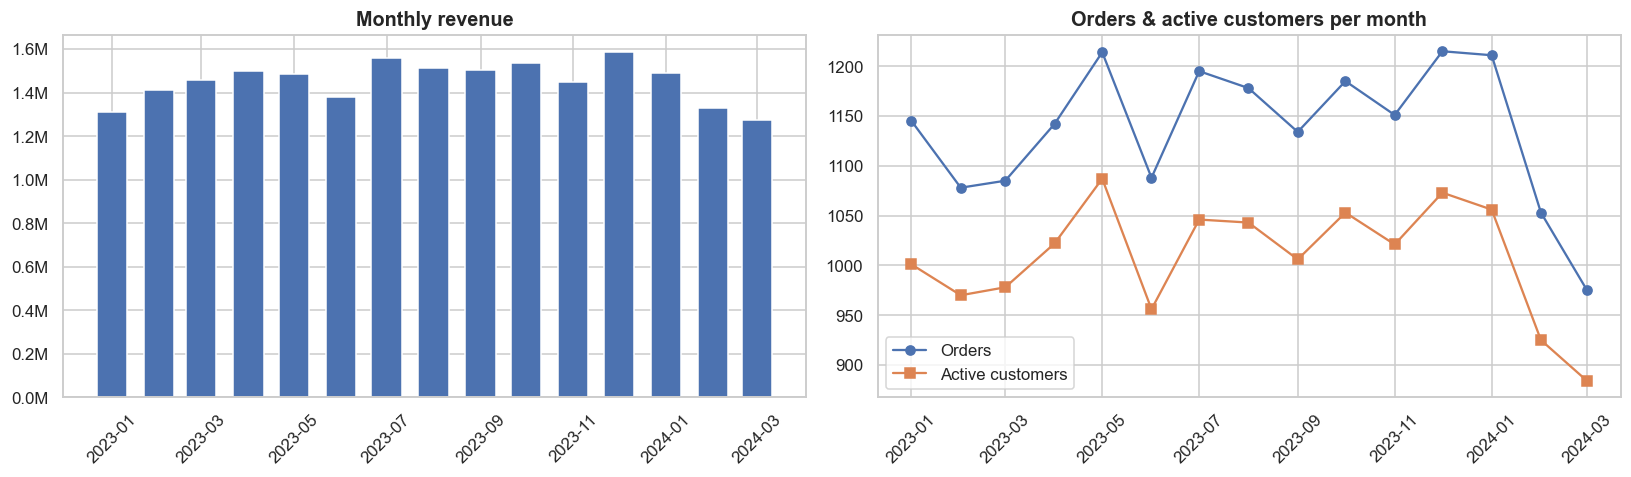

,Revenue,Orders,Customers,AOV
YearMonth,,,,
2023-10-01,"1,536,847.33",1185,1053,"1,296.92"
2023-11-01,"1,446,439.79",1151,1021,"1,256.68"
2023-12-01,"1,586,213.77",1215,1073,"1,305.53"
2024-01-01,"1,490,824.78",1211,1056,"1,231.07"
2024-02-01,"1,329,884.01",1053,925,"1,262.95"
2024-03-01,"1,272,101.99",975,884,"1,304.72"


In [8]:
monthly = df.groupby('YearMonth').agg(Revenue=('Total_Amount','sum'),
                                       Orders=('Order_ID','count'),
                                       Customers=('Customer_ID','nunique'))
monthly['AOV'] = monthly.Revenue / monthly.Orders
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(monthly.index, monthly.Revenue, width=20, color='#4c72b0')
ax[0].set_title('Monthly revenue'); ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,_: f'{v/1e6:.1f}M'))
ax[1].plot(monthly.index, monthly.Orders, marker='o', label='Orders')
ax[1].plot(monthly.index, monthly.Customers, marker='s', label='Active customers')
ax[1].set_title('Orders & active customers per month'); ax[1].legend()
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
monthly.tail(6)

In [9]:
best, worst = monthly.Revenue.idxmax(), monthly.Revenue.idxmin()
print(f'Peak month   : {best:%b %Y}  ({monthly.Revenue[best]:,.0f})')
print(f'Lowest month : {worst:%b %Y}  ({monthly.Revenue[worst]:,.0f})  <- note: {worst:%b %Y} may be a partial month' if worst==monthly.index[-1] else f'Lowest month : {worst:%b %Y}  ({monthly.Revenue[worst]:,.0f})')

Peak month   : Dec 2023  (1,586,214)
Lowest month : Mar 2024  (1,272,102)  <- note: Mar 2024 may be a partial month


### 4.3 Product categories, cities & devices

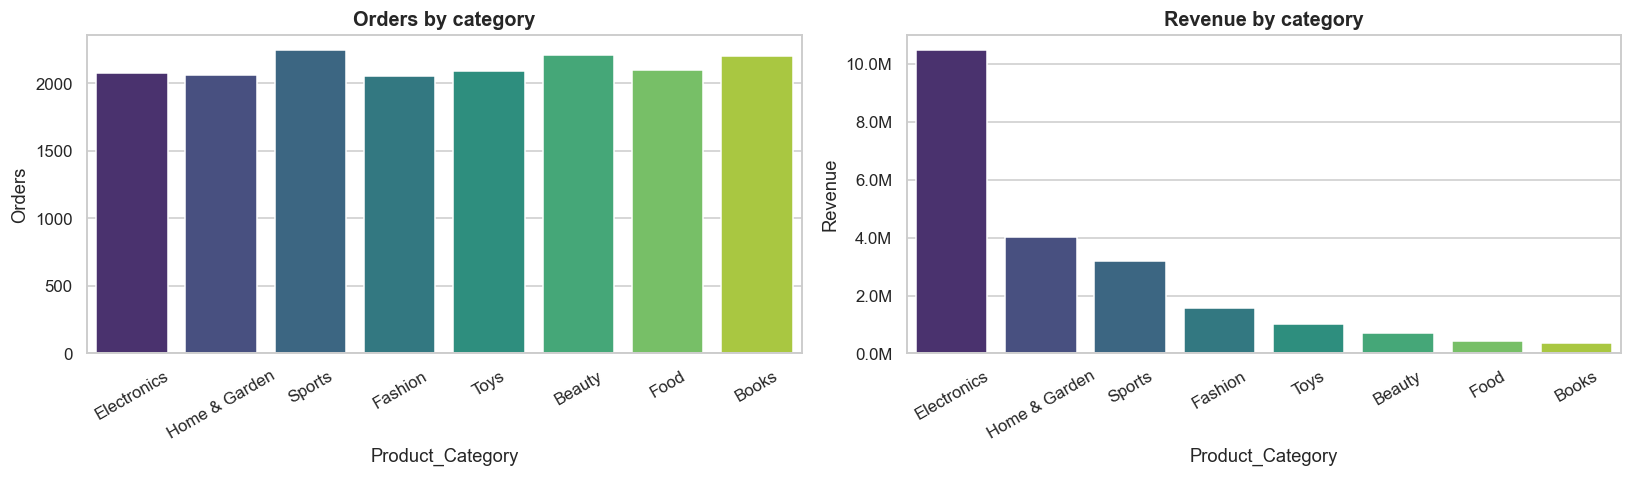

,Revenue,Orders,AOV,Rating,Rev_Share
Product_Category,,,,,
Electronics,"10,481,897.65",2074,"5,053.95",3.90,0.48
Home & Garden,"4,023,903.94",2060,"1,953.35",3.93,0.18
Sports,"3,205,086.99",2248,"1,425.75",3.92,0.15
Fashion,"1,577,035.70",2056,767.04,3.89,0.07
Toys,"1,014,237.53",2090,485.28,3.90,0.05
Beauty,"694,437.02",2212,313.94,3.92,0.03
Food,"422,054.65",2103,200.69,3.86,0.02
Books,"360,399.11",2206,163.37,3.88,0.02


In [10]:
cat = df.groupby('Product_Category').agg(Revenue=('Total_Amount','sum'), Orders=('Order_ID','count'),
                                         AOV=('Total_Amount','mean'), Rating=('Customer_Rating','mean')).sort_values('Revenue', ascending=False)
cat['Rev_Share'] = cat.Revenue / cat.Revenue.sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(x=cat.index, y=cat.Orders, ax=ax[0], palette='viridis'); ax[0].set_title('Orders by category'); ax[0].tick_params(axis='x', rotation=30)
sns.barplot(x=cat.index, y=cat.Revenue, ax=ax[1], palette='viridis'); ax[1].set_title('Revenue by category')
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,_: f'{v/1e6:.1f}M')); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
cat

In [11]:
print(f"Order counts are almost equal across categories (max/min = {cat.Orders.max()/cat.Orders.min():.2f}x), "
      f"but revenue differs {cat.Revenue.max()/cat.Revenue.min():.0f}x because average order value differs {cat.AOV.max()/cat.AOV.min():.0f}x.")
print(f"-> {cat.index[0]} generates {cat.Rev_Share.iloc[0]:.0%} of revenue; the top 2 categories generate {cat.Rev_Share.iloc[:2].sum():.0%}.")

Order counts are almost equal across categories (max/min = 1.09x), but revenue differs 29x because average order value differs 31x.
-> Electronics generates 48% of revenue; the top 2 categories generate 67%.


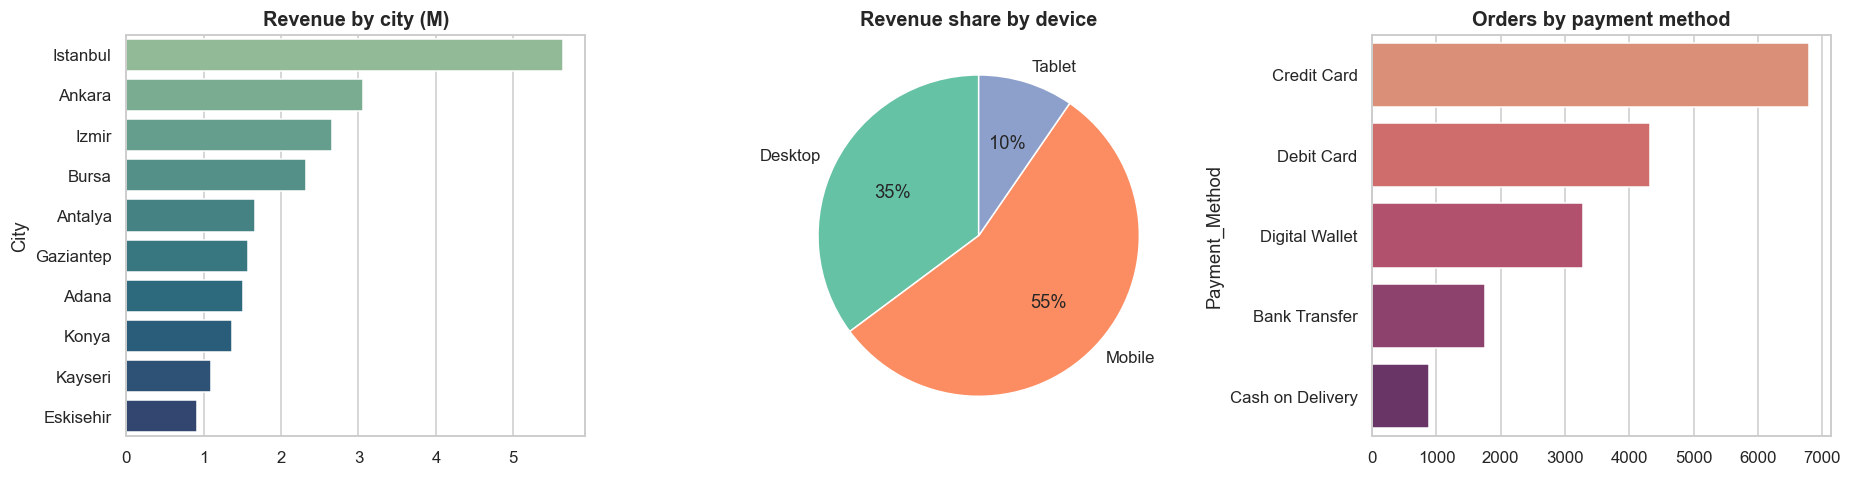

,Revenue,AOV
Device_Type,,
Desktop,"7,661,437.07","1,310.77"
Mobile,"12,028,685.29","1,260.47"
Tablet,"2,088,930.23","1,257.63"


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
city = df.groupby('City').Total_Amount.sum().sort_values(ascending=False)
sns.barplot(x=city.values/1e6, y=city.index, ax=ax[0], palette='crest'); ax[0].set_title('Revenue by city (M)')
dev = df.groupby('Device_Type').agg(Revenue=('Total_Amount','sum'), AOV=('Total_Amount','mean'))
ax[1].pie(dev.Revenue, labels=dev.index, autopct='%1.0f%%', startangle=90, colors=sns.color_palette('Set2')); ax[1].set_title('Revenue share by device')
pay = df.Payment_Method.value_counts()
sns.barplot(x=pay.values, y=pay.index, ax=ax[2], palette='flare'); ax[2].set_title('Orders by payment method')
plt.tight_layout(); plt.show()
dev

### 4.4 Customers: age & gender

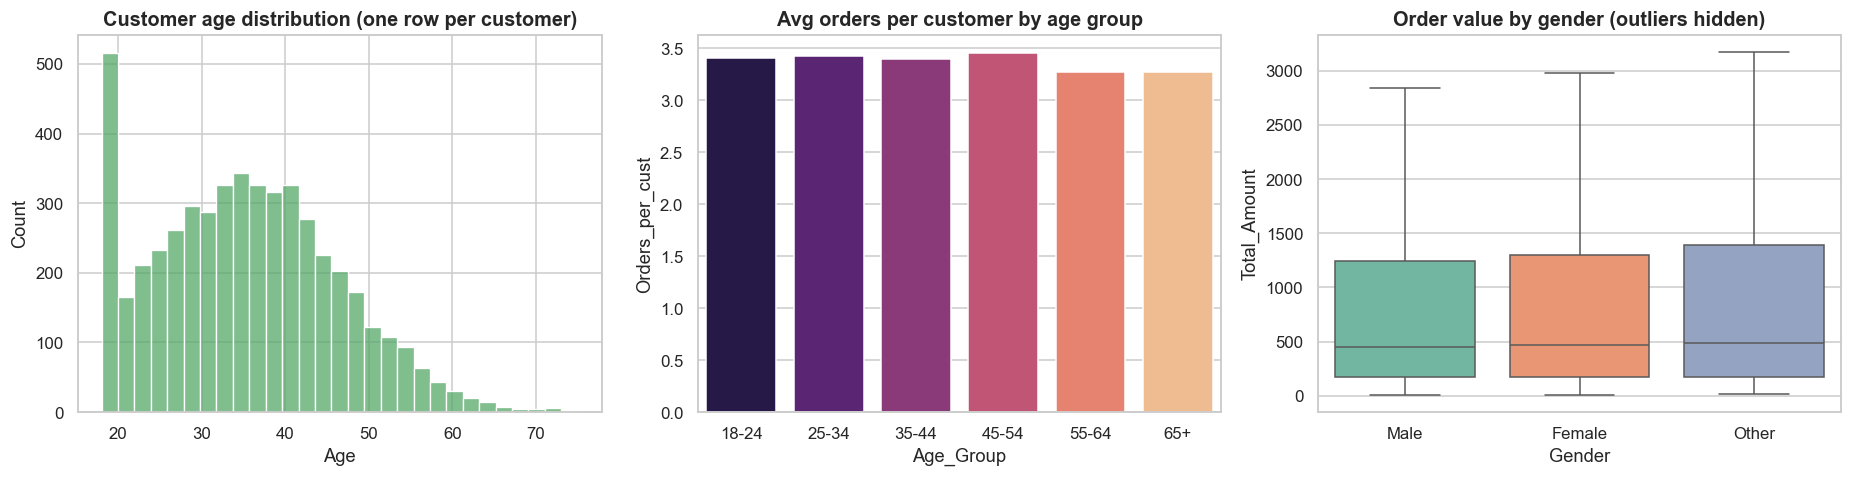

        count     mean  median
Gender                        
Female   8613 1,281.55  463.94
Male     8176 1,265.07  450.15
Other     260 1,530.32  482.78


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
cust_demo = df.drop_duplicates('Customer_ID')
sns.histplot(cust_demo.Age, bins=29, ax=ax[0], color='#55a868'); ax[0].set_title('Customer age distribution (one row per customer)')
ag = df.groupby('Age_Group').agg(Orders_per_cust=('Order_ID','count'), Revenue=('Total_Amount','sum'))
ag['Orders_per_cust'] = ag.Orders_per_cust / cust_demo.groupby('Age_Group').size()
sns.barplot(x=ag.index, y=ag.Orders_per_cust, ax=ax[1], palette='magma'); ax[1].set_title('Avg orders per customer by age group')
sns.boxplot(x='Gender', y='Total_Amount', data=df, ax=ax[2], palette='Set2', showfliers=False); ax[2].set_title('Order value by gender (outliers hidden)')
plt.tight_layout(); plt.show()
print(df.groupby('Gender').Total_Amount.agg(['count','mean','median']))

### 4.5 Engagement, discounts and satisfaction

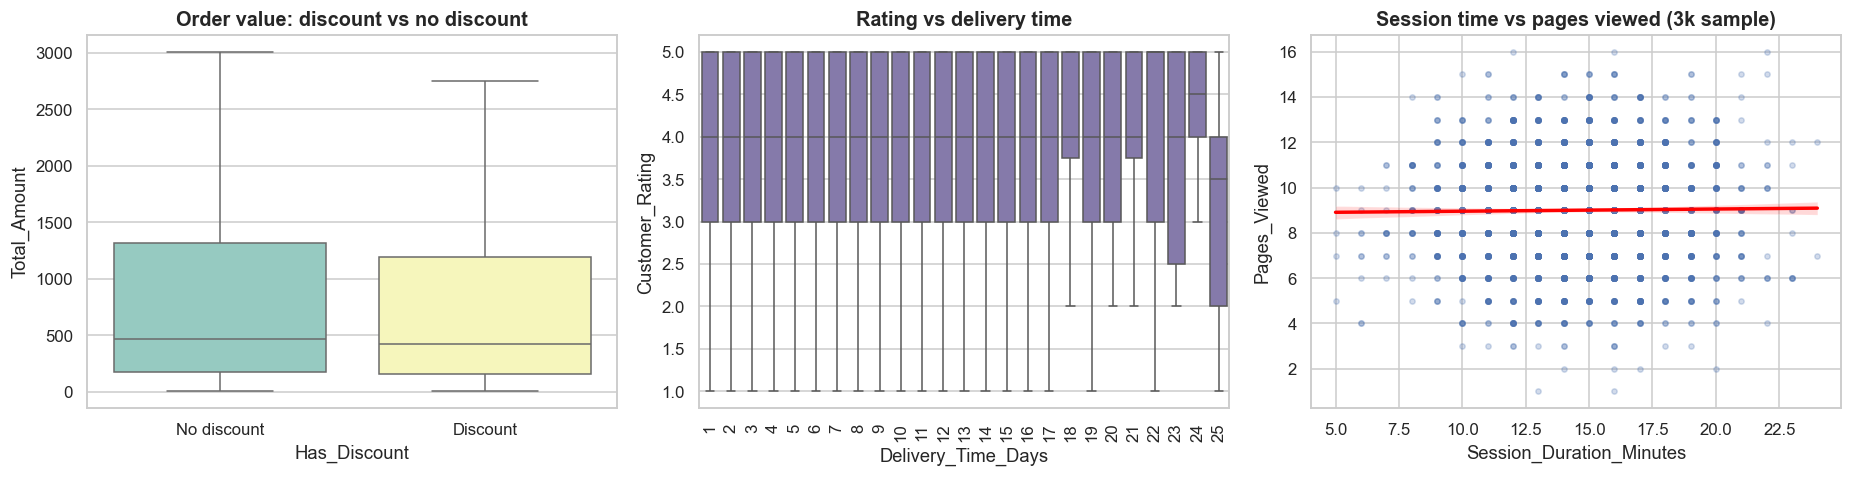

Discount effect:
              Orders      AOV  Median  Rating
Has_Discount                                 
False          10572 1,338.28  473.31    3.90
True            6477 1,178.13  428.02    3.90

Rating by delivery speed bucket:
                 count  mean
Delivery_Bucket             
1-3d              3332  3.91
4-7d              8221  3.90
8-14d             5021  3.89
15d+               475  3.86


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(x='Has_Discount', y='Total_Amount', data=df, ax=ax[0], palette='Set3', showfliers=False)
ax[0].set_title('Order value: discount vs no discount'); ax[0].set_xticklabels(['No discount','Discount'])
sns.boxplot(x='Delivery_Time_Days', y='Customer_Rating', data=df, ax=ax[1], color='#8172b2', showfliers=False)
ax[1].set_title('Rating vs delivery time'); ax[1].tick_params(axis='x', rotation=90)
sns.regplot(x='Session_Duration_Minutes', y='Pages_Viewed', data=df.sample(3000, random_state=RANDOM_STATE),
            scatter_kws={'alpha': .25, 's': 12}, line_kws={'color': 'red'}, ax=ax[2]); ax[2].set_title('Session time vs pages viewed (3k sample)')
plt.tight_layout(); plt.show()

print('Discount effect:')
print(df.groupby('Has_Discount').agg(Orders=('Order_ID','count'), AOV=('Total_Amount','mean'), Median=('Total_Amount','median'),
                                      Rating=('Customer_Rating','mean')))
print()
print('Rating by delivery speed bucket:')
df['Delivery_Bucket'] = pd.cut(df.Delivery_Time_Days, [0, 3, 7, 14, 30], labels=['1-3d','4-7d','8-14d','15d+'])
print(df.groupby('Delivery_Bucket').Customer_Rating.agg(['count','mean']))

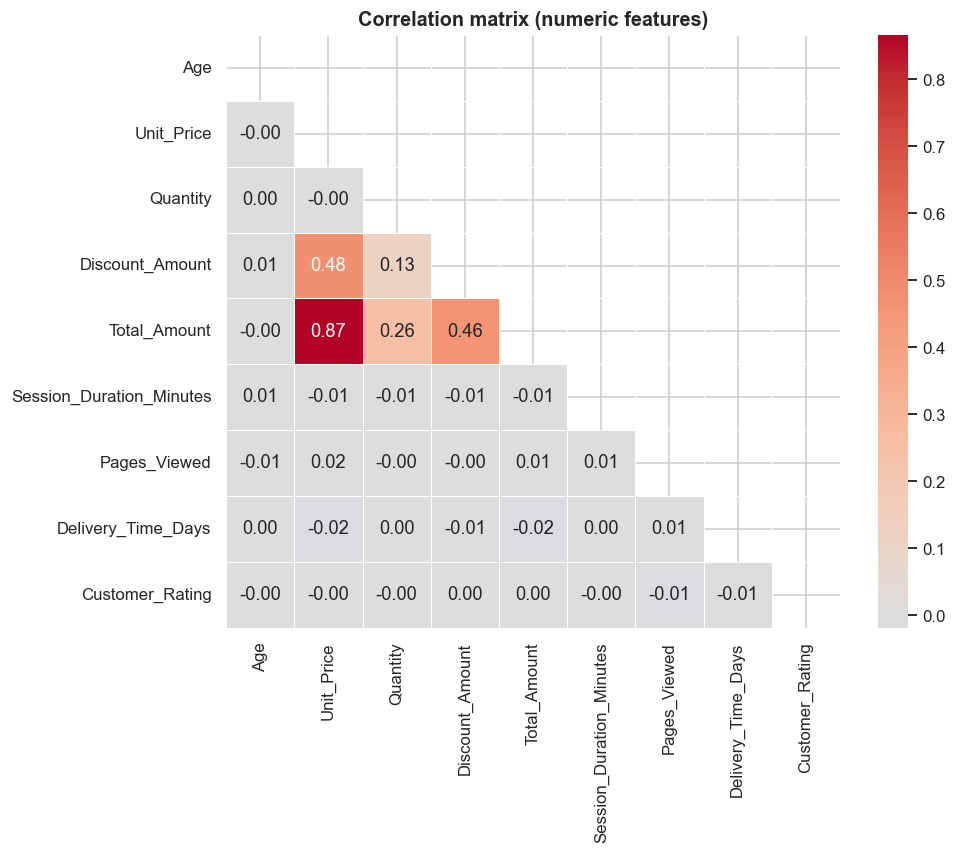

Pairs with |r| > 0.3:
Total_Amount     Unit_Price        0.87
Discount_Amount  Unit_Price        0.48
Total_Amount     Discount_Amount   0.46


In [15]:
num_cols = ['Age','Unit_Price','Quantity','Discount_Amount','Total_Amount','Session_Duration_Minutes',
            'Pages_Viewed','Delivery_Time_Days','Customer_Rating']
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', center=0, fmt='.2f', linewidths=.5)
plt.title('Correlation matrix (numeric features)'); plt.show()

strong = corr.where(~mask).stack().loc[lambda s: s.abs() > 0.3].sort_values(key=abs, ascending=False)
print('Pairs with |r| > 0.3:'); print(strong.round(2).to_string())

## 5. RFM analysis

**Definitions** (per customer):
- **Recency** – days since last purchase, measured from `snapshot = last date in data + 1 day`. *Lower is better.*
- **Frequency** – number of distinct orders.
- **Monetary** – total amount spent.

Each metric is cut into quintiles (1-5, 5 = best).

In [16]:
snapshot_date = df.Date.max() + pd.Timedelta(days=1)

rfm = df.groupby('Customer_ID').agg(
    Recency   = ('Date', lambda x: (snapshot_date - x.max()).days),
    Frequency = ('Order_ID', 'nunique'),
    Monetary  = ('Total_Amount', 'sum'),
    First_Purchase = ('Date', 'min'),
)
rfm['AOV'] = rfm.Monetary / rfm.Frequency
print('Snapshot date:', snapshot_date.date())
rfm[['Recency','Frequency','Monetary','AOV']].describe().T

Snapshot date: 2024-03-26


,count,mean,std,min,25%,50%,75%,max
Recency,"5,000.00",125.72,108.05,1.00,39.00,94.00,185.00,450.00
Frequency,"5,000.00",3.41,2.18,1.00,2.00,3.00,5.00,10.00
Monetary,"5,000.00","4,355.81","5,274.55",14.28,889.41,"2,493.93","5,796.30","50,628.15"
AOV,"5,000.00","1,262.89","1,539.04",14.28,387.12,794.48,"1,550.70","25,314.08"


In [17]:
# --- Scoring -----------------------------------------------------------------
# Frequency has only 10 distinct values with many ties, so plain qcut would fail / create arbitrary edges.
# We rank first and break ties by Monetary (a small, bounded tiebreaker that never crosses a frequency level).
freq_key = rfm.Frequency + rfm.Monetary.rank(pct=True) * 0.5

rfm['R_score'] = pd.qcut(rfm.Recency, 5, labels=[5,4,3,2,1]).astype(int)
rfm['F_score'] = pd.qcut(freq_key.rank(method='first'), 5, labels=[1,2,3,4,5]).astype(int)
rfm['M_score'] = pd.qcut(rfm.Monetary, 5, labels=[1,2,3,4,5]).astype(int)
rfm['RFM_Score'] = rfm.R_score.astype(str) + rfm.F_score.astype(str) + rfm.M_score.astype(str)
rfm['RFM_Total'] = rfm[['R_score','F_score','M_score']].sum(axis=1)
rfm[['R_score','F_score','M_score']].apply(pd.Series.value_counts).T

,1,2,3,4,5
R_score,999,997,972,1027,1005
F_score,1000,1000,1000,1000,1000
M_score,1000,1000,1000,1000,1000


In [18]:
# --- Segment map -------------------------------------------------------------
# Rules are mutually exclusive and exhaustive over the R x F grid (the old version had unreachable branches
# and relied on a catch-all 'else'). Monetary is used to prioritise *within* segments, see section 7.
def segment_customer(r, f):
    if r >= 4 and f >= 4: return 'Champions'
    if r >= 3 and f >= 3: return 'Loyal Customers'
    if r >= 4 and f == 1: return 'New Customers'
    if r >= 3:            return 'Potential Loyalists'   # R>=3 and F<=2 (excl. the new-customer case)
    if f >= 4:            return "Can't Lose Them"
    if f == 3:            return 'At Risk'
    if r == 2:            return 'About to Sleep'
    return 'Hibernating'                                   # R==1, F<=2

rfm['Segment'] = [segment_customer(r, f) for r, f in zip(rfm.R_score, rfm.F_score)]

SEG_ORDER = ['Champions','Loyal Customers','Potential Loyalists','New Customers',
             'About to Sleep',"Can't Lose Them",'At Risk','Hibernating']
SEG_COLORS = dict(zip(SEG_ORDER, ['#1b9e77','#66a61e','#a6d854','#7fc8f8','#ffd92f','#e6550d','#d95f02','#8c8c8c']))
assert rfm.Segment.isin(SEG_ORDER).all()

seg = rfm.groupby('Segment').agg(Customers=('Recency','size'),
                                 Avg_Recency=('Recency','mean'), Avg_Frequency=('Frequency','mean'),
                                 Avg_Monetary=('Monetary','mean'), Total_Revenue=('Monetary','sum')).reindex(SEG_ORDER)
seg['Pct_Customers'] = seg.Customers / seg.Customers.sum()
seg['Pct_Revenue']   = seg.Total_Revenue / seg.Total_Revenue.sum()
seg.style.format({'Avg_Recency':'{:.0f}','Avg_Frequency':'{:.1f}','Avg_Monetary':'{:,.0f}','Total_Revenue':'{:,.0f}',
                  'Pct_Customers':'{:.1%}','Pct_Revenue':'{:.1%}'}).background_gradient(subset=['Pct_Revenue'], cmap='Greens')

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Pct_Customers,Pct_Revenue
Segment,,,,,,,
Champions,1205,31,5.9,"7,990","9,628,486",24.1%,44.2%
Loyal Customers,1019,72,3.9,"4,912","5,005,500",20.4%,23.0%
Potential Loyalists,602,70,1.8,"1,474","887,511",12.0%,4.1%
New Customers,178,38,1.2,975,"173,597",3.6%,0.8%
About to Sleep,457,167,1.6,"1,591","726,960",9.1%,3.3%
Can't Lose Them,385,181,4.7,"7,185","2,766,226",7.7%,12.7%
At Risk,391,207,2.8,"3,991","1,560,549",7.8%,7.2%
Hibernating,763,318,1.4,"1,350","1,030,225",15.3%,4.7%


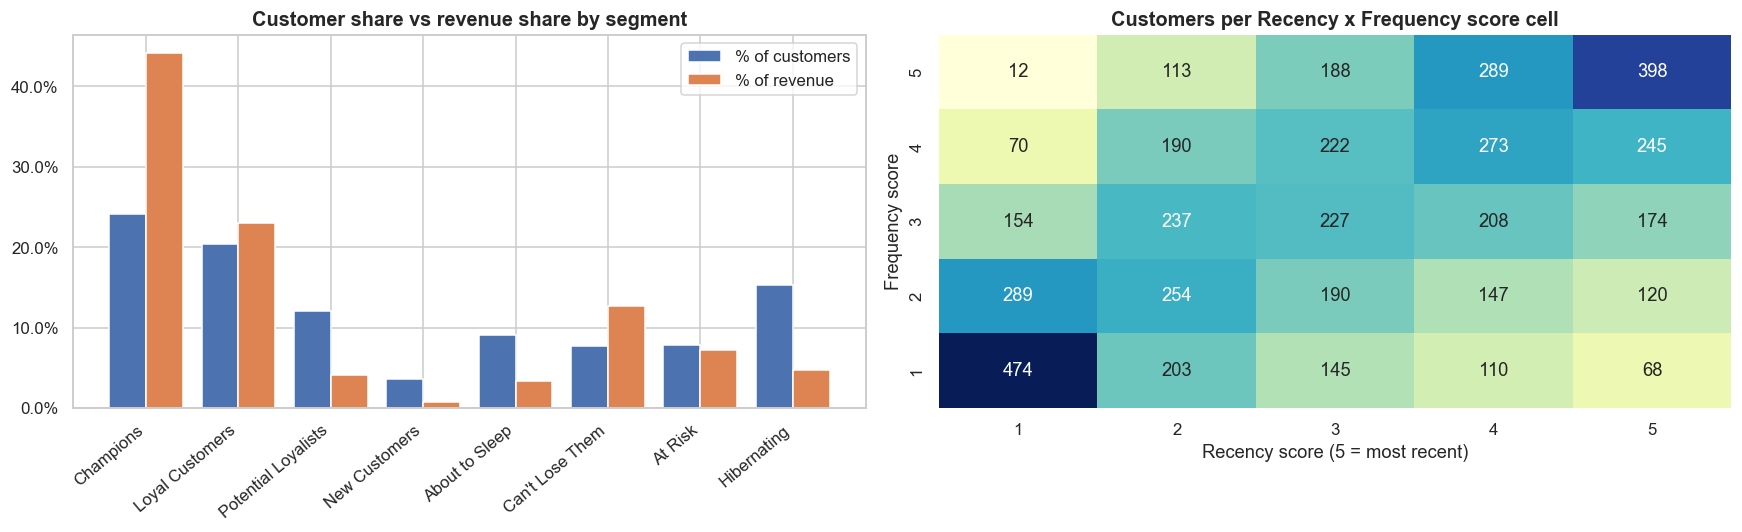

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(SEG_ORDER)); w = .4
ax[0].bar(x - w/2, seg.Pct_Customers*100, w, label='% of customers', color='#4c72b0')
ax[0].bar(x + w/2, seg.Pct_Revenue*100,   w, label='% of revenue',   color='#dd8452')
ax[0].set_xticks(x); ax[0].set_xticklabels(SEG_ORDER, rotation=40, ha='right'); ax[0].legend()
ax[0].set_title('Customer share vs revenue share by segment'); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter())

# Recency x Frequency grid with customer counts
grid = rfm.pivot_table(index='F_score', columns='R_score', values='Monetary', aggfunc='size').fillna(0).astype(int).sort_index(ascending=False)
sns.heatmap(grid, annot=True, fmt='d', cmap='YlGnBu', ax=ax[1], cbar=False)
ax[1].set_title('Customers per Recency x Frequency score cell'); ax[1].set_xlabel('Recency score (5 = most recent)'); ax[1].set_ylabel('Frequency score')
plt.tight_layout(); plt.show()

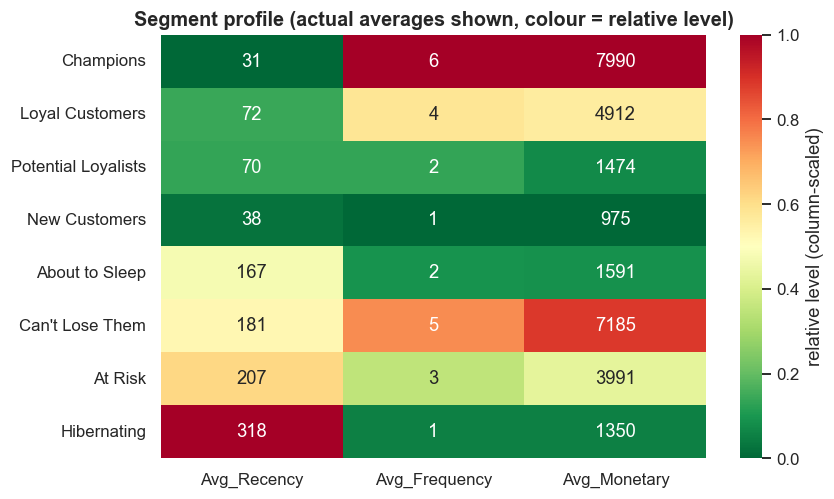

In [20]:
# RFM profile heatmap (each column min-max scaled so different units are comparable)
prof = seg[['Avg_Recency','Avg_Frequency','Avg_Monetary']].copy()
prof_n = (prof - prof.min()) / (prof.max() - prof.min())
plt.figure(figsize=(8, 5))
sns.heatmap(prof_n, annot=prof.round(0), fmt='.0f', cmap='RdYlGn_r', cbar_kws={'label': 'relative level (column-scaled)'})
plt.title('Segment profile (actual averages shown, colour = relative level)'); plt.ylabel(''); plt.show()

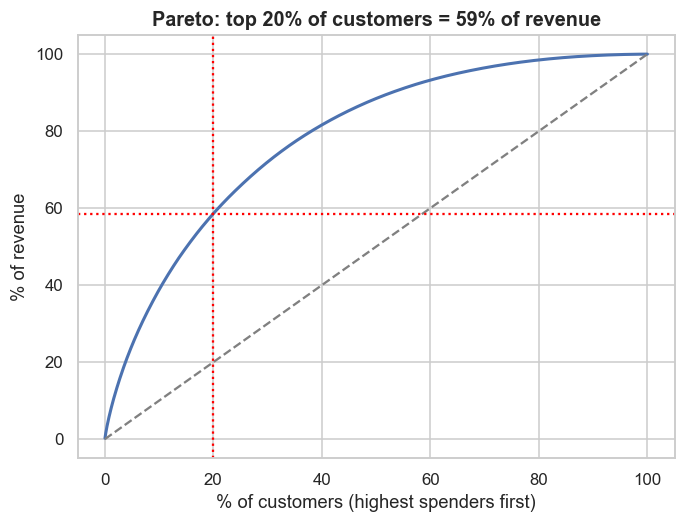

In [21]:
# Revenue concentration (Pareto)
s = rfm.Monetary.sort_values(ascending=False).reset_index(drop=True)
cum_rev = s.cumsum() / s.sum(); cum_cust = (np.arange(len(s)) + 1) / len(s)
top20 = cum_rev[int(.2*len(s)) - 1]
plt.figure(figsize=(7, 5))
plt.plot(cum_cust*100, cum_rev*100, lw=2); plt.plot([0,100],[0,100],'--',c='grey')
plt.axvline(20, c='red', ls=':'); plt.axhline(top20*100, c='red', ls=':')
plt.title(f'Pareto: top 20% of customers = {top20:.0%} of revenue')
plt.xlabel('% of customers (highest spenders first)'); plt.ylabel('% of revenue'); plt.show()

## 6. K-Means clustering

1. **log-transforming** Frequency and Monetary (Recency is closer to uniform and is left as-is),
2. **standardising**,
3. choosing *k* using **inertia + silhouette + Davies-Bouldin** (not the elbow alone), and
4. using `random_state` and `n_init` for reproducibility.

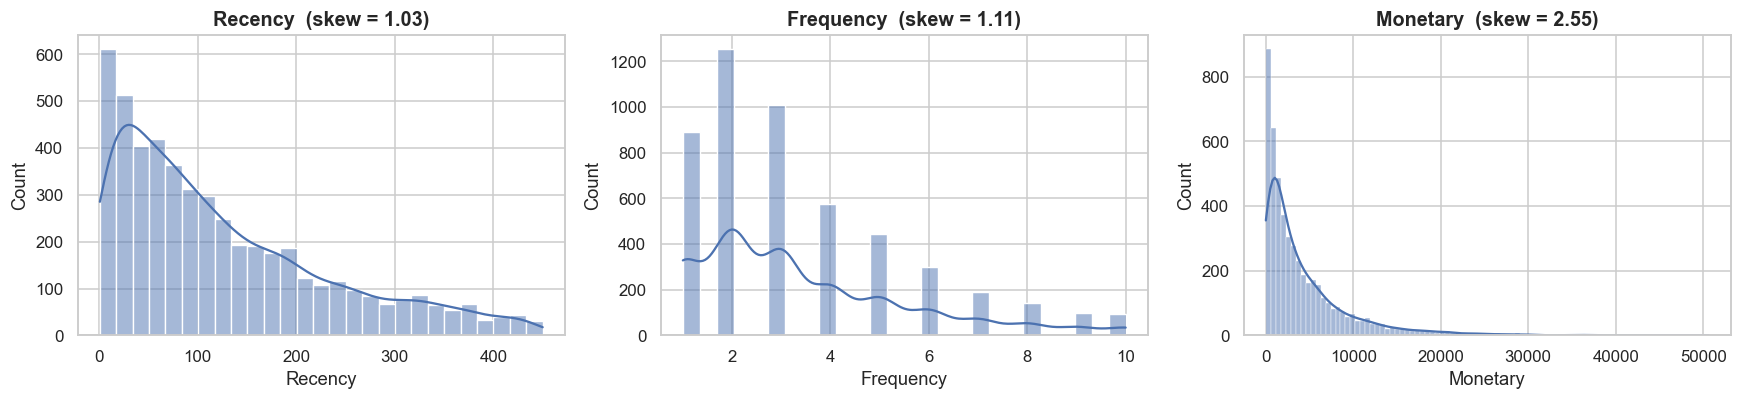

Skew after log1p: {'Recency': -0.8, 'Frequency': 0.24, 'Monetary': -0.52}


In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, c in zip(ax, ['Recency','Frequency','Monetary']):
    sns.histplot(rfm[c], kde=True, ax=a, color='#4c72b0'); a.set_title(f'{c}  (skew = {rfm[c].skew():.2f})')
plt.tight_layout(); plt.show()
print('Skew after log1p:', {c: round(np.log1p(rfm[c]).skew(), 2) for c in ['Recency','Frequency','Monetary']})

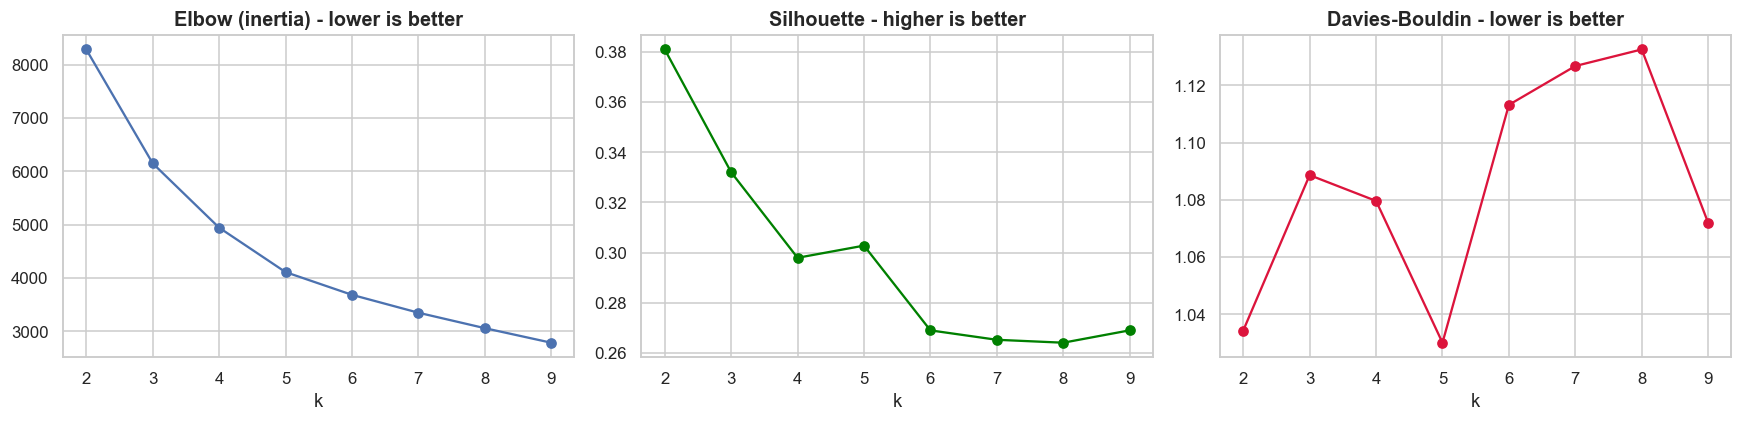

,Inertia,Silhouette,Davies_Bouldin
k,,,
2,"8,284.39",0.38,1.03
3,"6,148.15",0.33,1.09
4,"4,941.54",0.30,1.08
5,"4,107.96",0.30,1.03
6,"3,681.64",0.27,1.11
7,"3,346.01",0.27,1.13
8,"3,056.18",0.26,1.13
9,"2,783.19",0.27,1.07


In [34]:
X = rfm[['Recency','Frequency','Monetary']].copy()
X['Frequency'] = np.log1p(X.Frequency)
X['Monetary']  = np.log1p(X.Monetary)
X_scaled = StandardScaler().fit_transform(X)

rows = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    rows.append({'k': k, 'Inertia': km.inertia_,
                 'Silhouette': silhouette_score(X_scaled, km.labels_),
                 'Davies_Bouldin': davies_bouldin_score(X_scaled, km.labels_)})
k_eval = pd.DataFrame(rows).set_index('k')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
k_eval.Inertia.plot(marker='o', ax=ax[0], title='Elbow (inertia) - lower is better')
k_eval.Silhouette.plot(marker='o', ax=ax[1], color='green', title='Silhouette - higher is better')
k_eval.Davies_Bouldin.plot(marker='o', ax=ax[2], color='crimson', title='Davies-Bouldin - lower is better')
for a in ax: a.set_xlabel('k'); a.grid(True)
plt.tight_layout(); plt.show()
k_eval

In [24]:
# Selection: highest silhouette among business-usable k (3-6 segments).
usable = k_eval.loc[3:6]
K = int(usable.Silhouette.idxmax())
print(f'Chosen k = {K}  (silhouette {k_eval.Silhouette[K]:.3f})')

kmeans = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X_scaled)
rfm['Cluster'] = kmeans.labels_

clus = rfm.groupby('Cluster').agg(Customers=('Recency','size'), Avg_Recency=('Recency','mean'),
                                  Avg_Frequency=('Frequency','mean'), Avg_Monetary=('Monetary','mean'),
                                  Total_Revenue=('Monetary','sum'))
clus['Pct_Customers'] = clus.Customers / clus.Customers.sum()
clus['Pct_Revenue']   = clus.Total_Revenue / clus.Total_Revenue.sum()
clus

Chosen k = 3  (silhouette 0.332)


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Pct_Customers,Pct_Revenue
Cluster,,,,,,,
0,1862,90.96,2.23,"1,735.34","3,231,200.72",0.37,0.15
1,2092,70.53,5.34,"7,994.21","16,723,885.96",0.42,0.77
2,1046,297.96,1.65,"1,743.75","1,823,965.91",0.21,0.08


In [25]:
# Data-driven, readable cluster names based on where each centroid sits relative to the whole base
med = rfm[['Recency','Frequency','Monetary']].median()
def name_cluster(r):
    recent = r.Avg_Recency <= med.Recency
    freq   = r.Avg_Frequency >= med.Frequency
    money  = r.Avg_Monetary >= med.Monetary
    if recent and freq and money: return 'VIP / High Value'
    if recent and freq:           return 'Active Regulars'
    if recent and money:          return 'Recent Big Spenders'
    if recent:                    return 'Recent Low Spenders'
    if freq and money:            return 'Lapsed High Value'
    if freq:                      return 'Lapsed Regulars'
    return 'Lapsed / Low Value'

clus['Name'] = clus.apply(name_cluster, axis=1)
# disambiguate duplicate names, if any
dup = clus.Name.duplicated(keep=False)
clus.loc[dup, 'Name'] = clus.loc[dup, 'Name'] + ' #' + clus.loc[dup].groupby('Name').cumcount().add(1).astype(str)
rfm['Cluster_Name'] = rfm.Cluster.map(clus.Name)
clus.set_index('Name').drop(columns='Total_Revenue').style.format(
    {'Avg_Recency':'{:.0f}','Avg_Frequency':'{:.1f}','Avg_Monetary':'{:,.0f}','Pct_Customers':'{:.1%}','Pct_Revenue':'{:.1%}'})

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Pct_Customers,Pct_Revenue
Name,,,,,,
Recent Low Spenders,1862,91,2.2,"1,735",37.2%,14.8%
VIP / High Value,2092,71,5.3,"7,994",41.8%,76.8%
Lapsed / Low Value,1046,298,1.7,"1,744",20.9%,8.4%


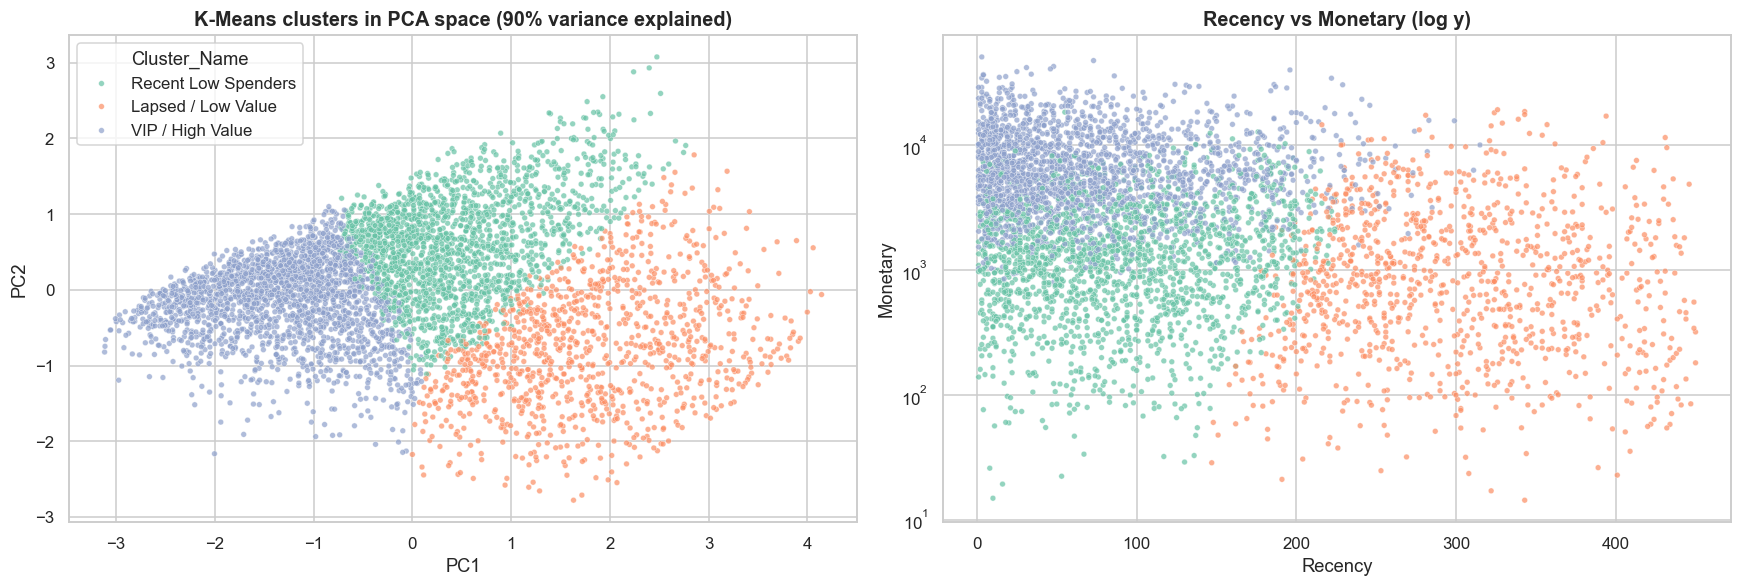

In [26]:
# Visual check: project the 3D scaled space to 2D with PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X_scaled)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(x=P[:,0], y=P[:,1], hue=rfm.Cluster_Name, palette='Set2', s=14, alpha=.7, ax=ax[0])
ax[0].set_title(f'K-Means clusters in PCA space ({pca.explained_variance_ratio_.sum():.0%} variance explained)')
ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2')
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Cluster_Name', palette='Set2', s=14, alpha=.7, ax=ax[1], legend=False)
ax[1].set_yscale('log'); ax[1].set_title('Recency vs Monetary (log y)')
plt.tight_layout(); plt.show()

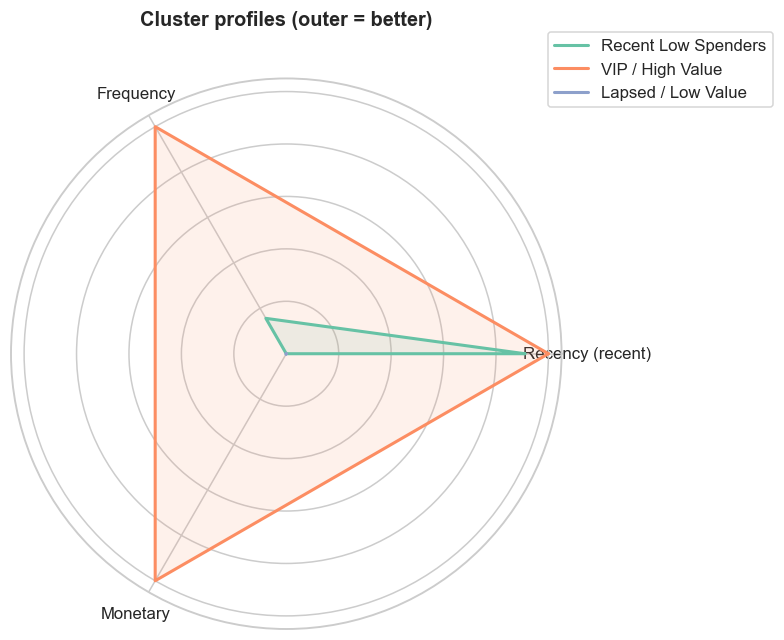

In [27]:
# Radar chart of cluster centroids (min-max scaled; Recency inverted so "outer = better" for all axes)
cent = clus.set_index('Name')[['Avg_Recency','Avg_Frequency','Avg_Monetary']].copy()
cent_n = (cent - cent.min()) / (cent.max() - cent.min()).replace(0, 1)
cent_n['Avg_Recency'] = 1 - cent_n['Avg_Recency']
labels = ['Recency (recent)','Frequency','Monetary']
ang = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist(); ang += ang[:1]
fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw=dict(polar=True))
for (n, row), col in zip(cent_n.iterrows(), sns.color_palette('Set2', len(cent_n))):
    v = row.tolist() + row.tolist()[:1]; ax.plot(ang, v, label=n, color=col, lw=2); ax.fill(ang, v, alpha=.12, color=col)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels); ax.set_yticklabels([])
ax.set_title('Cluster profiles (outer = better)', y=1.08); ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1))
plt.show()

## 7. Comparing RFM segments with K-Means clusters

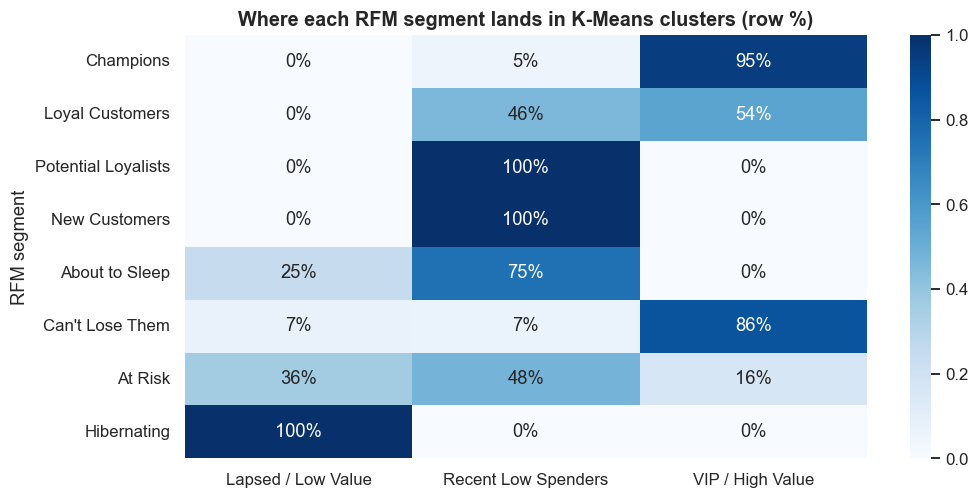

Adjusted Rand Index between the two segmentations: 0.335 (1 = identical, 0 = unrelated)


In [28]:
ct = pd.crosstab(rfm.Segment, rfm.Cluster_Name).reindex(SEG_ORDER)
ct_pct = ct.div(ct.sum(axis=1), axis=0)
plt.figure(figsize=(10, 5))
sns.heatmap(ct_pct, annot=True, fmt='.0%', cmap='Blues'); plt.title('Where each RFM segment lands in K-Means clusters (row %)')
plt.ylabel('RFM segment'); plt.xlabel(''); plt.show()
print(f'Adjusted Rand Index between the two segmentations: {adjusted_rand_score(rfm.Segment, rfm.Cluster_Name):.3f} '
      f'(1 = identical, 0 = unrelated)')

**To read this:** the rule-based RFM segments are easy to explain and map to concrete campaigns; K-Means finds natural groupings in the data without
predefined thresholds. Where they agree you can be confident; where an RFM segment is split across clusters, it usually hides different spend levels.
In practice, use **RFM segments as the operational labels** and K-Means as a sanity check / for finding sub-groups


## 8. Customer retention (monthly cohorts)

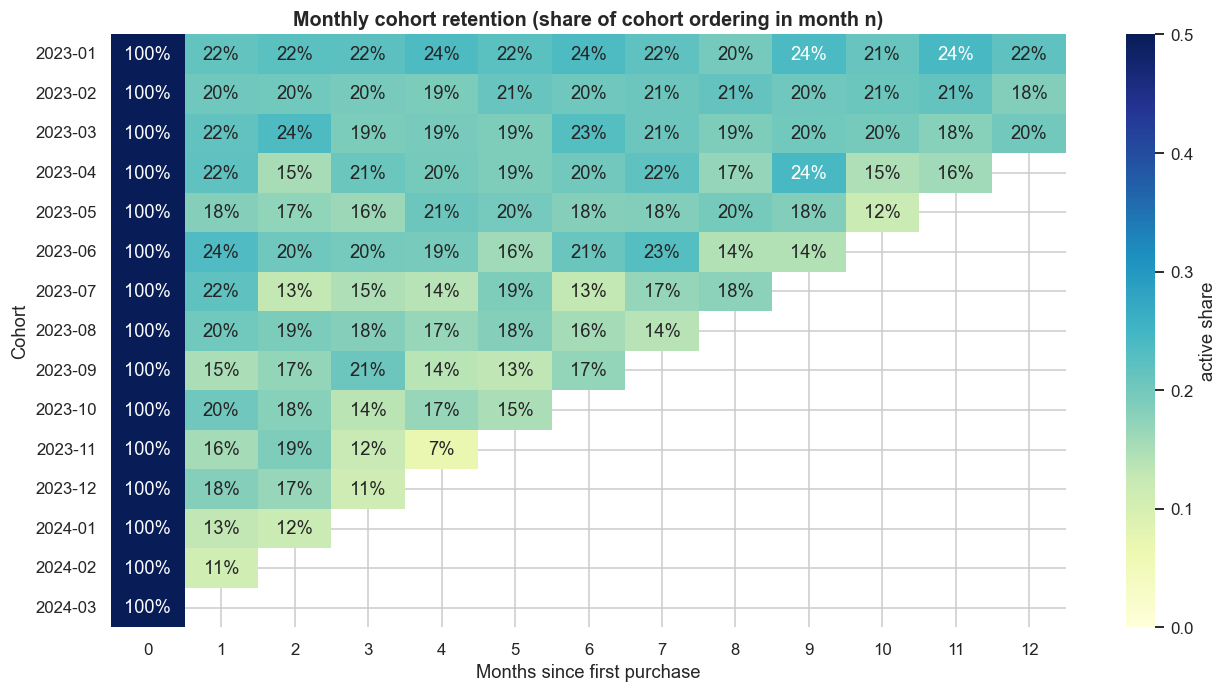

Avg retention by month since first purchase:
Period
1   0.17
2   0.16
3   0.14
4   0.13
5   0.12
6   0.12


In [29]:
first = df.groupby('Customer_ID').Date.min().dt.to_period('M').rename('Cohort')
d = df.join(first, on='Customer_ID')
d['Period'] = (d.YearMonth - d.Cohort).apply(lambda x: x.n)
coh = d.groupby(['Cohort','Period']).Customer_ID.nunique().unstack(fill_value=0)
ret = coh.div(coh[0], axis=0)

plt.figure(figsize=(14, 7))
sns.heatmap(ret.iloc[:, :13].where(ret.iloc[:, :13] > 0), annot=True, fmt='.0%', cmap='YlGnBu', vmin=0, vmax=.5, cbar_kws={'label': 'active share'})
plt.title('Monthly cohort retention (share of cohort ordering in month n)'); plt.xlabel('Months since first purchase'); plt.ylabel('Cohort')
plt.show()
cohort_sizes = coh[0]
print('Avg retention by month since first purchase:')
print(ret.iloc[:, 1:7].mean().round(3).to_string())

## 9. Actionable segment playbook

In [30]:
playbook = pd.DataFrame({
 'Segment': SEG_ORDER,
 'Who they are': ['Bought recently, buy often','Recent and fairly frequent','Recent, still building a habit','First purchase, very recent',
                  'Slipping away, low frequency',"Used to buy often - now silent",'Frequent buyers going quiet','Long gone, bought rarely'],
 'Recommended action': ['VIP perks, early access, referral programme; avoid heavy discounting',
                        'Cross-sell / bundles, loyalty points, ask for reviews',
                        'Second-purchase nudges, category recommendations, small incentive',
                        'Welcome series, onboarding, easy 2nd order incentive',
                        'Reminder emails, limited-time offer',
                        'Personal outreach, win-back offer, survey to find out why they left',
                        'Win-back campaign with personalised recommendations',
                        'Low-cost reactivation only; suppress from paid campaigns after a final attempt'],
}).set_index('Segment')
playbook = playbook.join(seg[['Customers','Pct_Customers','Pct_Revenue','Avg_Monetary']])
playbook.style.format({'Pct_Customers':'{:.1%}','Pct_Revenue':'{:.1%}','Avg_Monetary':'{:,.0f}'}).set_properties(
    subset=['Who they are','Recommended action'], **{'text-align': 'left', 'white-space': 'normal'})

,Who they are,Recommended action,Customers,Pct_Customers,Pct_Revenue,Avg_Monetary
Segment,,,,,,
Champions,"Bought recently, buy often","VIP perks, early access, referral programme; avoid heavy discounting",1205,24.1%,44.2%,"7,990"
Loyal Customers,Recent and fairly frequent,"Cross-sell / bundles, loyalty points, ask for reviews",1019,20.4%,23.0%,"4,912"
Potential Loyalists,"Recent, still building a habit","Second-purchase nudges, category recommendations, small incentive",602,12.0%,4.1%,"1,474"
New Customers,"First purchase, very recent","Welcome series, onboarding, easy 2nd order incentive",178,3.6%,0.8%,975
About to Sleep,"Slipping away, low frequency","Reminder emails, limited-time offer",457,9.1%,3.3%,"1,591"
Can't Lose Them,Used to buy often - now silent,"Personal outreach, win-back offer, survey to find out why they left",385,7.7%,12.7%,"7,185"
At Risk,Frequent buyers going quiet,Win-back campaign with personalised recommendations,391,7.8%,7.2%,"3,991"
Hibernating,"Long gone, bought rarely",Low-cost reactivation only; suppress from paid campaigns after a final attempt,763,15.3%,4.7%,"1,350"


In [31]:
# Where is the money at risk? Lapsed segments that used to be high-value.
at_risk = rfm[rfm.Segment.isin(["Can't Lose Them", 'At Risk'])]
print(f"'Can't Lose Them' + 'At Risk': {len(at_risk):,} customers ({len(at_risk)/len(rfm):.1%}) holding "
      f"{at_risk.Monetary.sum()/rfm.Monetary.sum():.1%} of historical revenue -> top win-back priority.")
top_winback = at_risk.sort_values('Monetary', ascending=False).head(10)[['Recency','Frequency','Monetary','Segment']]
top_winback

'Can't Lose Them' + 'At Risk': 776 customers (15.5%) holding 19.9% of historical revenue -> top win-back priority.


,Recency,Frequency,Monetary,Segment
Customer_ID,,,,
CUST_03149,196,6,"39,834.61",Can't Lose Them
CUST_03123,222,9,"34,205.20",Can't Lose Them
CUST_04643,124,6,"30,547.13",Can't Lose Them
CUST_00899,186,5,"30,453.57",Can't Lose Them
CUST_03958,229,4,"30,300.57",Can't Lose Them
CUST_00720,131,8,"30,076.86",Can't Lose Them
CUST_03084,139,2,"29,427.77",At Risk
CUST_01864,133,7,"29,280.80",Can't Lose Them
CUST_02856,187,2,"29,249.71",At Risk


## 10. Export results

In [32]:
out = rfm.reset_index().drop(columns=['First_Purchase']).merge(
        cust_demo[['Customer_ID','Age','Gender','City']], on='Customer_ID', how='left')
out.to_csv('customer_segments.csv', index=False)
seg.reset_index().to_csv('segment_summary.csv', index=False)
clus.to_csv('kmeans_cluster_summary.csv', index=False)
print('Saved: customer_segments.csv, segment_summary.csv, kmeans_cluster_summary.csv')
out.head()

Saved: customer_segments.csv, segment_summary.csv, kmeans_cluster_summary.csv


,Customer_ID,Recency,Frequency,Monetary,AOV,R_score,F_score,M_score,RFM_Score,RFM_Total,Segment,Cluster,Cluster_Name,Age,Gender,City
0,CUST_00001,112,3,"2,199.63",733.21,3,3,3,333,9,Loyal Customers,0,Recent Low Spenders,40,Male,Ankara
1,CUST_00002,284,2,809.90,404.95,1,2,2,122,5,Hibernating,2,Lapsed / Low Value,33,Male,Istanbul
2,CUST_00003,83,2,"3,030.81","1,515.40",3,2,3,323,8,Potential Loyalists,0,Recent Low Spenders,42,Male,Konya
3,CUST_00004,42,1,383.22,383.22,4,1,1,411,6,New Customers,0,Recent Low Spenders,53,Male,Izmir
4,CUST_00005,279,3,"2,422.73",807.58,1,3,3,133,7,At Risk,2,Lapsed / Low Value,32,Male,Ankara


## 11. Key findings

- **Revenue is concentrated.** The top 20% of customers generate ~59% of revenue; the 1,205 *Champions* (24% of customers) alone bring 44%.
- **Electronics drives the money, not the volume.** Order counts are nearly equal across the 8 categories, but Electronics is 48% of revenue (avg order ~5,054 vs ~163 for Books).
- **Discounts don't show a rating or basket lift.** Discounted orders have a lower average value (1,178 vs 1,338) and identical ratings (3.90). Worth testing whether the 38% discount share is buying real incremental volume.
- **Delivery speed barely moves ratings** (3.91 for 1-3 days vs 3.86 for 15+ days), so satisfaction is driven by something not in this data.
- **Win-back opportunity:** *Can't Lose Them* + *At Risk* are 15.5% of customers and 19.9% of historical revenue, and have gone quiet for ~6-7 months on average.
- **Retention is low:** only ~17% of a cohort orders again in month 1, falling to ~12% by month 6, so the first-to-second purchase is the key leverage point.
- **K-Means finds 3 broad groups** (high-value active, recent low spenders, lapsed). Silhouette is highest at k=3 (0.33), and moderate overall because RFM data forms a continuum rather than distinct blobs. The 8-segment RFM map is the more actionable view.
- Mar 2024 data stops on the 25th, so its lower revenue is a partial month, not a decline.

*(Numbers above come from the run on this dataset; re-run the notebook after data refreshes.)*

## 12. Summary & next steps

**What changed vs. the original notebook**
- Added a data-quality report and verified revenue reconciles with price, quantity and discount.
- Added time trends, category/city/device/discount/satisfaction analysis and a business KPI table.
- Corrected the age insight (per-customer comparison instead of raw counts).
- Rebuilt RFM scoring (quintiles, deterministic tie-breaking) and a **mutually exclusive segment map** (previous rules had unreachable branches, and the final K-Means labelling function was never applied).
- K-Means now uses log-transform + scaling, reproducible seeds and silhouette / Davies-Bouldin for choosing *k*; clusters are profiled, named and compared with RFM.
- Added Pareto analysis, cohort retention, a segment action playbook and CSV exports.

**Possible next steps**
- Predict churn / next-purchase probability (e.g. BG/NBD + Gamma-Gamma for customer lifetime value).
- A/B test the playbook actions on matched segments to measure uplift.
- Add product-affinity analysis (market basket) per segment.